# Member 4 — PPO clipping sensitivity in Snake

I compare clipping parameters 0.1, 0.2 and 0.3 in the shared Snake environment. The board is 8×8, the observation has seven channels, and actions are relative left, right and straight. Each game starts at length one, succeeds at length eight (seven foods), and has a 300-step limit. The original sparse reward is retained.

The final experiment contains **15 independent training runs of 500,000 interactions each**, followed by **200 held-out test games per selected checkpoint**. This submission contains the final models and results. Separate validation-only development was used to fix the training configuration before formal testing.

## Method

The Actor produces a categorical policy, while the Critic predicts discounted return. PPO uses fresh rollouts and repeats a limited number of optimization passes. It does not use a long-term replay buffer.

$$\delta_t=r_t+\gamma m_tV(o_{t+1})-V(o_t),\qquad\hat A_t=\delta_t+\gamma\lambda m_t\hat A_{t+1}.$$

Here $m_t=0$ after a game-ending transition. At a rollout boundary within a game, I bootstrap from the next observation. The 300-step limit is treated as the finite task horizon. The value target is $\hat R_t=\hat A_t+V_{old}(o_t)$, before normalizing the Actor advantages.

$$\rho_t=\pi_\theta(a_t\mid o_t)/\pi_{old}(a_t\mid o_t),$$
$$L^{clip}=\mathbb E[\min(\rho_t\hat A_t,\operatorname{clip}(\rho_t,1-\epsilon,1+\epsilon)\hat A_t)].$$

The minimized loss also includes value error and an entropy bonus. Clipping is not a strict bound on every actual probability change.

## Training configuration

- Orthogonal initialization, with a small policy-head gain of 0.01, starts the policy close to uniform.
- Adam uses epsilon $10^{-5}$.
- Learning rate decreases linearly from 0.0003 to 0.00003.
- Rollouts contain up to 1,024 transitions, with minibatches of 256 and up to six update epochs.
- Updates on the current batch stop early when its minibatch approximate KL exceeds 0.03, after at least one update. This is a heuristic safeguard, not a guarantee of a KL bound.
- Entropy coefficient decreases linearly from 0.02 to 0.005.

The settings were fixed before formal testing. All clipping settings use the same optimizer, network sizes, entropy schedule and interaction budget.

## Formal protocol

| Item | Value |
|---|---|
| Training seeds | 7, 42, 2026, 31415, 27182 |
| Clip | 0.1, 0.2, 0.3 |
| Budget per model | 500,000 interactions |
| Discount / GAE lambda | 0.99 / 0.95 |
| Value coefficient / gradient norm limit | 0.5 / 0.5 |
| Validation | 50 games every 25,000 steps, plus initialization |
| Validation seeds | 2601000–2601049 |
| Final test seeds | 2950000–2950199 |
| Final test | 200 greedy games per selected checkpoint |

Checkpoints are selected by validation mean food score, then success and reward to break ties. All clipping settings have identical budgets and other hyperparameters. Each model is evaluated on the same test scenes. The independent training seed is the unit of replication.



In [1]:
# Exported from the executed experiment notebook; no training on import.
from pathlib import Path
import importlib.util
import json, csv, hashlib, platform, random, time
from collections import Counter, deque
from dataclasses import dataclass
from typing import Any, ClassVar

RUN_SMOKE = False
TRAIN_MODEL = False
ROOT = Path.cwd()
ROOT.mkdir(parents=True, exist_ok=True)
required = ["numpy", "torch", "gymnasium", "pygame", "matplotlib", "PIL"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError("Install these packages and restart the kernel: " + ", ".join(missing))

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym
from gymnasium import spaces
import pygame
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display, Markdown, Image as DisplayImage

torch.set_num_threads(1)
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__)
print("Outputs:", ROOT)


Python: 3.14.7 | PyTorch: 2.14.1
Outputs: /Users/apple/.codex/.chatgpt-projects/g-p-6aac209f2ef08191a77943746763ecb7/output/member4/Member4_Final_Submission


/Users/apple/.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /var/folders/x3/8g1gfmd54j38lb0g5hmlfb780000gn/T/matplotlib-khu3la3m because there was an issue with the default path ({configdir}); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


In [2]:
class SnakeEnv(gym.Env[np.ndarray, int]):
    metadata: ClassVar[dict[str, Any]] = {'render_modes': ['human'], 'render_fps': 30}
    direction_channels: ClassVar[dict[tuple[int, int], int]] = {(-1, 0): 3, (1, 0): 4, (0, -1): 5, (0, 1): 6}

    def __init__(self, grid_size: int=8, end_score: int=8, max_steps: int=300, render_mode: str | None=None, reward_mode: str='sparse', teacher_mode: str='shortest_path') -> None:
        super().__init__()
        if grid_size < 5:
            raise ValueError('grid_size must be at least 5')
        if end_score < 2:
            raise ValueError('end_score must be at least 2')
        if max_steps < 1:
            raise ValueError('max_steps must be positive')
        if render_mode not in {None, 'human'}:
            raise ValueError("render_mode must be None or 'human'")
        if reward_mode not in {'sparse', 'dense'}:
            raise ValueError("reward_mode must be 'sparse' or 'dense'")
        if teacher_mode not in {'shortest_path', 'legacy'}:
            raise ValueError("teacher_mode must be 'shortest_path' or 'legacy'")
        self.grid_size = grid_size
        self.end_score = end_score
        self.max_steps = max_steps
        self.render_mode = render_mode
        self.reward_mode = reward_mode
        self.teacher_mode = teacher_mode
        self.action_space = spaces.Discrete(3)
        self.observation_space = spaces.Box(low=0, high=1, shape=(7, grid_size, grid_size), dtype=np.float32)
        self.snake: list[np.ndarray] = []
        self.food_pos = np.zeros(2, dtype=np.int64)
        self.current_direction = np.array([0, 1], dtype=np.int64)
        self.score = 0
        self.step_count = 0
        self.visited: set[tuple[int, int]] = set()
        self.visited_positions: list[np.ndarray] = []
        self.game_over = False
        self.window: pygame.Surface | None = None
        self.clock: pygame.time.Clock | None = None
        self.closed = False

    def reset(self, *, seed: int | None=None, options: dict[str, Any] | None=None) -> tuple[np.ndarray, dict[str, Any]]:
        super().reset(seed=seed)
        del options
        self.snake = [self._get_center_position()]
        self.current_direction = np.array([0, 1], dtype=np.int64)
        self.food_pos = self._generate_food()
        self.score = 0
        self.step_count = 0
        self.visited.clear()
        self.visited_positions.clear()
        self.game_over = False
        self.closed = False
        observation = self._get_observation()
        if self.render_mode == 'human':
            self.render()
        return (observation, self._info(executed_action=None))

    def step(self, action: int) -> tuple[np.ndarray, float, bool, bool, dict[str, Any]]:
        if self.game_over:
            raise RuntimeError('episode is finished; call reset() before step()')
        if not self.action_space.contains(action):
            raise ValueError(f'invalid action {action!r}; expected 0, 1, or 2')
        executed_action = int(action)
        self.current_direction = self._get_direction(executed_action)
        new_head = self.snake[0] + self.current_direction
        self.step_count += 1
        if self._is_collision(new_head):
            reward = -5.0
            terminated = True
        else:
            reward = self._calculate_reward(new_head)
            reward_delta, terminated = self._update_snake_and_food(new_head)
            reward += reward_delta
        truncated = self.step_count >= self.max_steps and (not terminated)
        self.game_over = terminated or truncated
        observation = self._get_observation()
        info = self._info(executed_action=executed_action)
        if self.render_mode == 'human':
            self.render()
        return (observation, float(reward), terminated, truncated, info)

    def teacher_action(self) -> int:
        if self.teacher_mode == 'legacy':
            return self._teacher_action_legacy()
        candidates: list[tuple[int, int]] = []
        for action in range(self.action_space.n):
            trial_head = self.snake[0] + self._get_direction(action)
            if not self._is_safe(trial_head):
                continue
            steps = self._shortest_path_to_food(trial_head)
            if steps is not None:
                candidates.append((steps, action))
        if candidates:
            return min(candidates)[1]
        fallback: list[tuple[int, int]] = []
        for action in range(self.action_space.n):
            trial_head = self.snake[0] + self._get_direction(action)
            if self._is_safe(trial_head):
                fallback.append((self._reachable_space(trial_head), action))
        if fallback:
            return max(fallback)[1]
        return 2

    def _teacher_action_legacy(self) -> int:
        candidates: list[tuple[float, int]] = []
        for action in range(self.action_space.n):
            trial_head = self.snake[0] + self._get_direction(action)
            if self._is_safe(trial_head) and self._bfs_safe_path(trial_head):
                distance = float(np.abs(trial_head - self.food_pos).sum())
                candidates.append((distance, action))
        if not candidates:
            return 2
        return min(candidates)[1]

    def _info(self, executed_action: int | None) -> dict[str, Any]:
        return {'score': self.score, 'length': len(self.snake), 'steps': self.step_count, 'executed_action': executed_action}

    def _is_safe(self, position: np.ndarray) -> bool:
        if np.any(position < 0) or np.any(position >= self.grid_size):
            return False
        return tuple(position) not in map(tuple, self.snake[1:])

    def _bfs_safe_path(self, position: np.ndarray, depth: int=11) -> bool:
        directions = (np.array([-1, 0]), np.array([1, 0]), np.array([0, -1]), np.array([0, 1]))
        queue: deque[np.ndarray] = deque([position])
        blocked = set(map(tuple, self.snake[1:]))
        visited = {tuple(position)}
        required_cells = min(depth, self.grid_size * self.grid_size - len(blocked))
        while queue:
            current = queue.popleft()
            if len(visited) >= required_cells:
                return True
            for direction in directions:
                candidate = current + direction
                candidate_key = tuple(candidate)
                in_bounds = np.all(candidate >= 0) and np.all(candidate < self.grid_size)
                if in_bounds and candidate_key not in blocked and (candidate_key not in visited):
                    queue.append(candidate)
                    visited.add(candidate_key)
        return False

    def _bfs_distances(self, position: np.ndarray) -> dict[tuple[int, int], int]:
        directions = (np.array([-1, 0]), np.array([1, 0]), np.array([0, -1]), np.array([0, 1]))
        blocked = set(map(tuple, self.snake[1:]))
        start = tuple(position)
        distances: dict[tuple[int, int], int] = {}
        if start in blocked:
            return distances
        queue: deque[tuple[tuple[int, int], int]] = deque([(start, 0)])
        distances[start] = 0
        while queue:
            current, distance = queue.popleft()
            for direction in directions:
                candidate = (current[0] + int(direction[0]), current[1] + int(direction[1]))
                if not (0 <= candidate[0] < self.grid_size and 0 <= candidate[1] < self.grid_size):
                    continue
                if candidate in blocked or candidate in distances:
                    continue
                distances[candidate] = distance + 1
                queue.append((candidate, distance + 1))
        return distances

    def _shortest_path_to_food(self, position: np.ndarray) -> int | None:
        return self._bfs_distances(position).get(tuple(self.food_pos))

    def _reachable_space(self, position: np.ndarray) -> int:
        return len(self._bfs_distances(position))

    def _get_direction(self, action: int) -> np.ndarray:
        if action == 0:
            return np.array([-self.current_direction[1], self.current_direction[0]])
        if action == 1:
            return np.array([self.current_direction[1], -self.current_direction[0]])
        return self.current_direction.copy()

    def _calculate_reward(self, new_head: np.ndarray) -> float:
        if self.reward_mode == 'sparse':
            return -0.5 if self._check_repeated_visit() else 0.0
        distance_before = np.abs(self.snake[0] - self.food_pos).sum()
        distance_after = np.abs(new_head - self.food_pos).sum()
        reward = 0.2 if distance_after < distance_before else -0.1
        if tuple(new_head) not in self.visited:
            reward += 0.2
            self.visited.add(tuple(new_head))
        if self._check_repeated_visit():
            reward -= 0.4
        return reward

    def _update_snake_and_food(self, new_head: np.ndarray) -> tuple[float, bool]:
        self.snake.insert(0, new_head)
        reward = 0.0
        if np.array_equal(new_head, self.food_pos):
            self.score += 1
            self.food_pos = self._generate_food()
            reward += 10.0
        else:
            self.snake.pop()
            reward -= 0.01
        self.visited_positions.append(new_head.copy())
        terminated = len(self.snake) >= self.end_score
        if terminated:
            reward += 100.0
        return (reward, terminated)

    def _check_repeated_visit(self) -> bool:
        if len(self.visited_positions) < 5:
            return False
        counts = Counter(map(tuple, self.visited_positions[-5:]))
        return any((count >= 2 for count in counts.values()))

    def _get_observation(self) -> np.ndarray:
        grid = np.zeros((7, self.grid_size, self.grid_size), dtype=np.float32)
        for segment in self.snake:
            grid[0, int(segment[0]), int(segment[1])] = 1.0
        grid[1, int(self.food_pos[0]), int(self.food_pos[1])] = 1.0
        grid[2, :, :] = 1.0
        grid[2, 1:-1, 1:-1] = 0.0
        direction_channel = self.direction_channels[tuple(self.current_direction)]
        grid[direction_channel, :, :] = 1.0
        return grid

    def _is_collision(self, position: np.ndarray) -> bool:
        if np.any(position < 0) or np.any(position >= self.grid_size):
            return True
        return tuple(position) in map(tuple, self.snake[1:])

    def _generate_food(self) -> np.ndarray:
        occupied = set(map(tuple, self.snake))
        head_ahead = tuple(self.snake[0] + self.current_direction)
        blocked = occupied | {head_ahead}
        free_cells = [(row, column) for row in range(self.grid_size) for column in range(self.grid_size) if (row, column) not in blocked]
        if not free_cells:
            free_cells = [(row, column) for row in range(self.grid_size) for column in range(self.grid_size) if (row, column) not in occupied]
        index = int(self.np_random.integers(len(free_cells)))
        return np.array(free_cells[index], dtype=np.int64)

    def _get_center_position(self) -> np.ndarray:
        return np.array([self.grid_size // 2, self.grid_size // 2], dtype=np.int64)

    def render(self, fps: int | None=None) -> None:
        if self.render_mode != 'human':
            return
        if self.window is None:
            pygame.init()
            self.cell_size = 20
            self.window = pygame.display.set_mode((self.grid_size * self.cell_size, self.grid_size * self.cell_size))
            pygame.display.set_caption('RL Snake')
            self.clock = pygame.time.Clock()
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self.closed = True
                self.close()
                return
        self.window.fill((18, 18, 18))
        for row in range(self.grid_size):
            for column in range(self.grid_size):
                rect = pygame.Rect(column * self.cell_size, row * self.cell_size, self.cell_size, self.cell_size)
                pygame.draw.rect(self.window, (48, 48, 48), rect, 1)
        food_row, food_column = self.food_pos
        pygame.draw.rect(self.window, (62, 201, 111), pygame.Rect(food_column * self.cell_size, food_row * self.cell_size, self.cell_size, self.cell_size))
        for index, (row, column) in enumerate(self.snake):
            color = (235, 87, 87) if index == 0 else (224, 132, 79)
            pygame.draw.rect(self.window, color, pygame.Rect(column * self.cell_size, row * self.cell_size, self.cell_size, self.cell_size))
        pygame.display.flip()
        if self.clock is not None:
            self.clock.tick(fps or self.metadata['render_fps'])

    def close(self) -> None:
        if self.window is not None:
            pygame.display.quit()
            self.window = None
        pygame.quit()


In [3]:
@dataclass(slots=True)
class RolloutBatch:
    states: torch.Tensor
    actions: torch.Tensor
    old_log_probabilities: torch.Tensor
    returns: torch.Tensor
    advantages: torch.Tensor

class PPOActorCritic(nn.Module):
    """Shared low-compute encoder with categorical policy and value heads."""

    def __init__(self, input_channels: int, action_count: int, grid_size: int, *, learning_rate: float, weight_decay: float) -> None:
        super().__init__()
        feature_dim = 16 * grid_size * grid_size
        self.encoder = nn.Sequential(nn.Conv2d(input_channels, 16, kernel_size=3, padding=1), nn.ReLU(), nn.Flatten(), nn.Linear(feature_dim, 64), nn.ReLU())
        self.actor = nn.Linear(64, action_count)
        self.critic = nn.Linear(64, 1)
        for layer in self.modules():
            if isinstance(layer, (nn.Linear, nn.Conv2d)):
                nn.init.orthogonal_(layer.weight, gain=2 ** 0.5)
                nn.init.zeros_(layer.bias)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.orthogonal_(self.critic.weight, gain=1.0)
        self.optimizer = torch.optim.Adam(self.parameters(), lr=learning_rate, weight_decay=weight_decay, eps=1e-5)

    def forward(self, observation: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        features = self.encoder(observation)
        return (self.actor(features), self.critic(features).squeeze(-1))

    @torch.no_grad()
    def predict(self, observation: torch.Tensor, *, deterministic: bool) -> int:
        logits, _ = self(observation)
        distribution = torch.distributions.Categorical(logits=logits)
        action = torch.argmax(logits, dim=-1) if deterministic else distribution.sample()
        return int(action.item())

class PPOAgent:
    """Categorical PPO using the same compact encoder as the Actor-Critic lesson."""

    def __init__(self, input_channels: int, action_count: int, grid_size: int, *, learning_rate: float=0.0003, weight_decay: float=0.0, device: torch.device | str='cpu') -> None:
        self.device = torch.device(device)
        self.model = PPOActorCritic(input_channels, action_count, grid_size, learning_rate=learning_rate, weight_decay=weight_decay).to(self.device)

    @torch.no_grad()
    def select_action(self, observation: np.ndarray) -> tuple[int, float, float]:
        state = torch.from_numpy(observation).unsqueeze(0).to(device=self.device, dtype=torch.float32)
        logits, value = self.model(state)
        distribution = torch.distributions.Categorical(logits=logits)
        action = distribution.sample()
        return (int(action.item()), float(distribution.log_prob(action).item()), float(value.item()))

    @torch.no_grad()
    def predict(self, observation: np.ndarray, *, deterministic: bool=False, generator: torch.Generator | None=None) -> int:
        state = torch.from_numpy(observation).unsqueeze(0).to(device=self.device, dtype=torch.float32)
        logits, _ = self.model(state)
        if deterministic:
            return int(torch.argmax(logits, dim=-1).item())
        probabilities = torch.softmax(logits, dim=-1)
        return int(torch.multinomial(probabilities, 1, generator=generator).item())

    def update(self, batch: RolloutBatch, *, update_epochs: int, batch_size: int, clip_ratio: float, value_coef: float, entropy_coef: float, max_grad_norm: float) -> dict[str, float]:
        sample_count = len(batch.actions)
        totals = {'loss': 0.0, 'policy_loss': 0.0, 'value_loss': 0.0, 'entropy': 0.0, 'approx_kl': 0.0, 'clip_fraction': 0.0}
        updates = 0
        for _ in range(update_epochs):
            indices = torch.randperm(sample_count, device=self.device)
            for start in range(0, sample_count, batch_size):
                selected = indices[start:start + batch_size]
                logits, values = self.model(batch.states[selected])
                distribution = torch.distributions.Categorical(logits=logits)
                new_log_probabilities = distribution.log_prob(batch.actions[selected])
                log_ratio = new_log_probabilities - batch.old_log_probabilities[selected]
                ratio = log_ratio.exp()
                with torch.no_grad():
                    kl = (ratio - 1 - log_ratio).mean()
                if updates and kl.item() > 0.03:
                    return {name: value / updates for name, value in totals.items()}
                unclipped = ratio * batch.advantages[selected]
                clipped = ratio.clamp(1.0 - clip_ratio, 1.0 + clip_ratio) * batch.advantages[selected]
                policy_loss = -torch.minimum(unclipped, clipped).mean()
                value_loss = 0.5 * F.mse_loss(values, batch.returns[selected])
                entropy = distribution.entropy().mean()
                loss = policy_loss + value_coef * value_loss - entropy_coef * entropy
                self.model.optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=max_grad_norm)
                self.model.optimizer.step()
                with torch.no_grad():
                    approximate_kl = (ratio - 1.0 - log_ratio).mean()
                    clip_fraction = ((ratio - 1.0).abs() > clip_ratio).float().mean()
                metrics = {'loss': loss, 'policy_loss': policy_loss, 'value_loss': value_loss, 'entropy': entropy, 'approx_kl': approximate_kl, 'clip_fraction': clip_fraction}
                for name, value in metrics.items():
                    totals[name] += float(value.detach())
                updates += 1
        return {name: value / updates for name, value in totals.items()}

    def save_checkpoint(self, filename: str | Path, *, episode: int, total_steps: int, config: dict[str, Any]) -> None:
        path = Path(filename)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({'algorithm': 'ppo', 'model_state_dict': self.model.state_dict(), 'optimizer_state_dict': self.model.optimizer.state_dict(), 'episode': episode, 'total_steps': total_steps, 'config': config}, path)

    def load_checkpoint(self, filename: str | Path) -> dict[str, Any]:
        checkpoint = torch.load(filename, map_location=self.device, weights_only=True)
        if checkpoint.get('algorithm') != 'ppo':
            raise ValueError('checkpoint is not a PPO checkpoint')
        self.model.load_state_dict(checkpoint['model_state_dict'])
        if 'optimizer_state_dict' in checkpoint:
            self.model.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        return {'episode': int(checkpoint.get('episode', -1)), 'total_steps': int(checkpoint.get('total_steps', 0)), 'config': dict(checkpoint.get('config', {}))}


In [4]:
def compute_gae(rewards, values, ends, next_value, gamma=0.99, lam=0.95):
    rewards, values, ends = map(lambda x: np.asarray(x, dtype=np.float32), (rewards, values, ends))
    if not (rewards.ndim == values.ndim == ends.ndim == 1 and len(rewards) == len(values) == len(ends)):
        raise ValueError('Expected equal-length vectors')
    advantages = np.zeros_like(rewards)
    running = 0.0
    for t in reversed(range(len(rewards))):
        continuation = 1.0 - ends[t]
        following = next_value if t == len(rewards) - 1 else values[t + 1]
        delta = rewards[t] + gamma * continuation * following - values[t]
        running = delta + gamma * lam * continuation * running
        advantages[t] = running
    return (advantages, advantages + values)

def write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')

def environment():
    return SnakeEnv(grid_size=8, end_score=8, max_steps=300, reward_mode='sparse')

def evaluate(agent, base, episodes):
    """Greedy policy, same environment seeds for every checkpoint; no RNG sampling."""
    env = environment()
    rows = []
    try:
        for seed in range(base, base + episodes):
            obs, info = env.reset(seed=seed)
            total = 0.0
            while True:
                obs, reward, terminal, timeout, info = env.step(agent.predict(obs, deterministic=True))
                total += reward
                if terminal or timeout:
                    rows.append(dict(episode_seed=seed, score=info['score'], steps=info['steps'], reward=total, success=int(info['length'] >= 8), timeout=int(timeout)))
                    break
    finally:
        env.close()
    return rows

def summary(rows):
    return {k: float(np.mean([r[k] for r in rows])) for k in ['score', 'steps', 'reward', 'success', 'timeout']}

def make_agent(learning_rate=0.0003):
    return PPOAgent(7, 3, 8, learning_rate=learning_rate, device='cpu')

def train(seed, clip, protocol, folder):
    folder.mkdir(parents=True, exist_ok=True)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    agent, env = (make_agent(protocol['learning_rate']), environment())
    episode = 0
    obs, _ = env.reset(seed=10000000 + seed * 100000)
    history, updates = ([], [])
    total_steps = 0
    best_key = (-float('inf'),) * 3

    def save(name):
        agent.save_checkpoint(folder / 'checkpoints' / name, episode=episode, total_steps=total_steps, config={**protocol, 'seed': seed, 'clip_ratio': clip})

    def validate():
        nonlocal best_key
        row = {**summary(evaluate(agent, protocol['validation_base'], protocol['validation_episodes'])), 'training_steps': total_steps}
        history.append(row)
        key = (row['score'], row['success'], row['reward'])
        if key > best_key:
            best_key = key
            save('best.pt')
        write_json(folder / 'validation.json', history)
        print(f"seed={seed} clip={clip} steps={total_steps} validation_score={row['score']:.3f}", flush=True)
    save('step-0.pt')
    validate()
    start = time.perf_counter()
    next_validation = protocol['eval_interval']
    milestones = {round(protocol['steps'] * f) for f in [0.25, 0.5, 0.75, 1.0]}
    try:
        while total_steps < protocol['steps']:
            next_boundary = min([x for x in milestones | {next_validation, protocol['steps']} if x > total_steps])
            size = min(protocol['rollout_steps'], next_boundary - total_steps)
            states, actions, rewards, ends, logs, values = ([], [], [], [], [], [])
            for _ in range(size):
                action, log_prob, value = agent.select_action(obs)
                nxt, reward, terminal, timeout, _ = env.step(action)
                states.append(obs.copy())
                actions.append(action)
                rewards.append(protocol['reward_scale'] * reward)
                ends.append(terminal or timeout)
                logs.append(log_prob)
                values.append(value)
                total_steps += 1
                obs = nxt
                if terminal or timeout:
                    episode += 1
                    obs, _ = env.reset(seed=10000000 + seed * 100000 + episode)
            with torch.no_grad():
                next_value = float(agent.model(torch.as_tensor(obs).unsqueeze(0))[1].item())
            advantage, returns = compute_gae(rewards, values, ends, next_value, gamma=protocol['gamma'], lam=protocol['gae_lambda'])
            a = torch.as_tensor(advantage)
            a = (a - a.mean()) / (a.std(unbiased=False) + 1e-08)
            batch = RolloutBatch(torch.as_tensor(np.stack(states)), torch.tensor(actions), torch.tensor(logs), torch.as_tensor(returns), a)
            for group in agent.model.optimizer.param_groups:
                group['lr'] = protocol['learning_rate'] * (1 - 0.9 * total_steps / protocol['steps'])
            metrics = agent.update(batch, update_epochs=protocol['update_epochs'], batch_size=protocol['batch_size'], clip_ratio=clip, value_coef=protocol['value_coef'], entropy_coef=protocol['entropy_coef'] + (protocol.get('entropy_final', protocol['entropy_coef']) - protocol['entropy_coef']) * total_steps / protocol['steps'], max_grad_norm=protocol['max_grad_norm'])
            updates.append({'steps': total_steps, **metrics})
            if total_steps in milestones:
                save(f'step-{total_steps}.pt')
            if total_steps == next_validation or total_steps == protocol['steps']:
                validate()
                next_validation += protocol['eval_interval']
        save('latest.pt')
    finally:
        env.close()
    write_json(folder / 'updates.json', updates)
    write_json(folder / 'trained.json', {'seed': seed, 'clip_ratio': clip, 'steps': total_steps, 'seconds_including_validation': time.perf_counter() - start})


In [5]:
def generate(folder):
    folder = Path(folder)
    rows = json.loads((folder / 'results.json').read_text())
    p = json.loads((folder / 'protocol.json').read_text())
    target = folder / 'figures'
    target.mkdir(exist_ok=True)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for clip in p['clips']:
        histories = [json.loads((folder / f'seed-{s}' / f'clip-{clip:.1f}' / 'validation.json').read_text()) for s in p['seeds']]
        xs = np.array([r.get('training_steps', index * p['eval_interval']) for index, r in enumerate(histories[0])])
        assert xs[-1] == p['steps'], 'Validation schedule and training budget disagree'
        for ax, metric in zip(axs, ['score', 'success']):
            ys = np.array([[r[metric] for r in h] for h in histories])
            mean = ys.mean(axis=0)
            std = ys.std(axis=0, ddof=1) if len(ys) > 1 else np.zeros(len(xs))
            ax.plot(xs, mean, label=f'clip={clip}')
            ax.fill_between(xs, mean - std, mean + std, alpha=0.15)
            ax.set(xlabel='Training environment steps', ylabel='Validation ' + metric)
            ax.legend()
            ax.grid(alpha=0.2)
    fig.suptitle('Mean and ±1 sample SD across training seeds')
    fig.tight_layout()
    fig.savefig(target / 'learning_curves.png', dpi=170)
    plt.close(fig)
    lines = ['# Observed results', '', f"Execution mode: **{p['mode']}**. Smoke results are pipeline checks, not final findings.", '', '| Clip | Test score (mean ± seed SD) | Success rate (mean ± seed SD) |', '|---|---:|---:|']
    for clip in p['clips']:
        subset = [r for r in rows if r['clip'] == clip]
        a = np.array([r['score'] for r in subset])
        b = np.array([r['success'] for r in subset])
        sd = lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else 0.0
        lines.append(f'| {clip} | {a.mean():.3f} ± {sd(a):.3f} | {100 * b.mean():.1f}% ± {100 * sd(b):.1f} pp |')
    lines += ['', 'The unit of replication is the training seed. Episode-level variation is not a substitute for independent training runs.', '', 'Paired differences relative to clip=0.2 (descriptive bootstrap intervals; only five seeds in final mode):', '']
    rng = np.random.default_rng(761)
    for clip in [0.1, 0.3]:
        differences = []
        for seed in p['seeds']:
            by = {r['clip']: r for r in rows if r['seed'] == seed}
            differences.append(by[clip]['score'] - by[0.2]['score'])
        d = np.array(differences)
        if len(d) > 1:
            boots = rng.choice(d, (10000, len(d)), replace=True).mean(axis=1)
            lo, hi = np.quantile(boots, [0.025, 0.975])
            lines.append(f'- clip={clip} minus 0.2: {d.mean():.3f}, paired bootstrap 95% interval [{lo:.3f}, {hi:.3f}].')
        else:
            lines.append(f'- clip={clip}: one training seed; no inferential interval.')
    lines += ['', 'Do not select or retune a configuration on these test results. A follow-up experiment needs new held-out seeds.', 'A positive mean difference alone does not establish a reliable improvement. Check individual seeds and learning curves.']
    (folder / 'observed_results.md').write_text('\n'.join(lines), encoding='utf-8')
    fig, ax = plt.subplots(figsize=(6, 4))
    for seed in p['seeds']:
        subset = sorted([r for r in rows if r['seed'] == seed], key=lambda r: r['clip'])
        ax.plot([r['clip'] for r in subset], [r['score'] for r in subset], '-o', label=f'seed {seed}')
    ax.set(xlabel='PPO clipping parameter', ylabel='Mean test food score', ylim=(0, 7.2))
    ax.legend()
    fig.tight_layout()
    fig.savefig(target / 'paired_scores.png', dpi=170)
    plt.close(fig)
    print(f'Wrote observed results and figures to {folder}')

class ConvActorCritic(nn.Module):
    """A compact shared encoder with categorical actor and state-value critic."""

    def __init__(self, input_channels: int, output_dim: int, grid_size: int, lr: float=0.0001, weight_decay: float=1e-05, entropy_coef: float=0.01) -> None:
        super().__init__()
        self.input_channels = input_channels
        self.output_dim = output_dim
        self.grid_size = grid_size
        self.entropy_coef = entropy_coef
        feature_dim = 16 * grid_size * grid_size
        self.feature_extractor = nn.Sequential(nn.Conv2d(input_channels, 16, kernel_size=3, stride=1, padding=1), nn.ReLU(), nn.Flatten())
        self.actor = nn.Linear(feature_dim, output_dim)
        self.critic = nn.Linear(feature_dim, 1)
        self.optimizer = torch.optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)

    def forward(self, observation: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        features = self.feature_extractor(observation)
        logits = self.actor(features)
        value = self.critic(features).squeeze(-1)
        return (logits, value)

    @torch.no_grad()
    def predict(self, observation: torch.Tensor, deterministic: bool=False) -> int:
        logits, _ = self(observation)
        distribution = torch.distributions.Categorical(logits=logits)
        action = torch.argmax(logits, dim=-1) if deterministic else distribution.sample()
        return int(action.item())

    def update(self, state: torch.Tensor, action: int | torch.Tensor, reward: float, next_state: torch.Tensor, done: bool, gamma: float=0.99) -> dict[str, float]:
        """Apply one correct one-step Actor-Critic update."""
        logits, value = self(state)
        with torch.no_grad():
            _, next_value = self(next_state)
            target = torch.as_tensor(reward, dtype=value.dtype, device=value.device)
            if not done:
                target = target + gamma * next_value
        action_tensor = torch.as_tensor(action, dtype=torch.long, device=value.device).reshape(-1)
        distribution = torch.distributions.Categorical(logits=logits)
        log_probability = distribution.log_prob(action_tensor)
        advantage = target - value
        actor_loss = -(log_probability * advantage.detach()).mean()
        critic_loss = 0.5 * advantage.square().mean()
        entropy = distribution.entropy().mean()
        loss = actor_loss + critic_loss - self.entropy_coef * entropy
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), max_norm=1.0)
        self.optimizer.step()
        return {'loss': float(loss.detach()), 'actor_loss': float(actor_loss.detach()), 'critic_loss': float(critic_loss.detach()), 'entropy': float(entropy.detach())}

    def imitation_update(self, state: torch.Tensor, teacher_action: int | torch.Tensor) -> float:
        """Learn an explicitly supplied teacher action with behavior cloning."""
        logits, _ = self(state)
        target = torch.as_tensor(teacher_action, dtype=torch.long, device=logits.device).reshape(-1)
        loss = F.cross_entropy(logits, target)
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), max_norm=1.0)
        self.optimizer.step()
        return float(loss.detach())

    def value_update(self, state: torch.Tensor, reward: float, next_state: torch.Tensor, done: bool, gamma: float=0.99) -> float:
        """Train the critic on a teacher transition without a policy-gradient update."""
        _, value = self(state)
        with torch.no_grad():
            _, next_value = self(next_state)
            target = torch.as_tensor(reward, dtype=value.dtype, device=value.device)
            if not done:
                target = target + gamma * next_value
        loss = 0.5 * (target - value).square().mean()
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), max_norm=1.0)
        self.optimizer.step()
        return float(loss.detach())

    def save_checkpoint(self, filename: str | Path, *, episode: int, config: dict[str, Any]) -> None:
        path = Path(filename)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({'model_state_dict': self.state_dict(), 'optimizer_state_dict': self.optimizer.state_dict(), 'episode': episode, 'config': config}, path)

    def load_checkpoint(self, filename: str | Path) -> dict[str, Any]:
        checkpoint = torch.load(filename, map_location=self.device, weights_only=True)
        self.load_state_dict(checkpoint['model_state_dict'])
        if 'optimizer_state_dict' in checkpoint:
            self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        return {'episode': int(checkpoint.get('episode', -1)), 'config': dict(checkpoint.get('config', {}))}

    @property
    def device(self) -> torch.device:
        return next(self.parameters()).device

class QNetwork(nn.Module):
    """Compact convolutional network that estimates one Q value per action."""

    def __init__(self, input_channels: int, action_count: int, grid_size: int) -> None:
        super().__init__()
        feature_dim = 16 * grid_size * grid_size
        self.network = nn.Sequential(nn.Conv2d(input_channels, 16, kernel_size=3, padding=1), nn.ReLU(), nn.Flatten(), nn.Linear(feature_dim, 64), nn.ReLU(), nn.Linear(64, action_count))

    def forward(self, observation: torch.Tensor) -> torch.Tensor:
        return self.network(observation)

class DuelingQNetwork(nn.Module):
    """Estimate state value and centered action advantages separately."""

    def __init__(self, input_channels: int, action_count: int, grid_size: int) -> None:
        super().__init__()
        feature_dim = 16 * grid_size * grid_size
        self.encoder = nn.Sequential(nn.Conv2d(input_channels, 16, kernel_size=3, padding=1), nn.ReLU(), nn.Flatten(), nn.Linear(feature_dim, 64), nn.ReLU())
        self.value_head = nn.Linear(64, 1)
        self.advantage_head = nn.Linear(64, action_count)

    def decompose(self, observation: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        features = self.encoder(observation)
        return (self.value_head(features), self.advantage_head(features))

    def forward(self, observation: torch.Tensor) -> torch.Tensor:
        value, advantage = self.decompose(observation)
        return value + advantage - advantage.mean(dim=1, keepdim=True)

def load_policy(path, grid):
    ck = torch.load(path, map_location='cpu', weights_only=True)
    if 'online_state_dict' in ck:

        state = ck['online_state_dict']
        dueling = ck.get('config', {}).get('dueling', False) or 'dueling' in ck.get('algorithm', '')
        net = (DuelingQNetwork if dueling else QNetwork)(7, 3, grid)
        net.load_state_dict(state)

        def policy(obs):
            return int(net(torch.as_tensor(obs).unsqueeze(0)).argmax(-1).item())
    else:
        state = ck['model_state_dict']
        if ck.get('algorithm') == 'ppo' or any((k.startswith('encoder.') for k in state)):

            net = PPOAgent(7, 3, grid).model
        else:

            net = ConvActorCritic(7, 3, grid)
        net.load_state_dict(state)

        def policy(obs):
            return int(net(torch.as_tensor(obs).unsqueeze(0))[0].argmax(-1).item())
    net.eval()
    return (policy, ck)

def frame(env, label, ended):
    cell = 25
    top = 52
    im = Image.new('RGB', (env.grid_size * cell, env.grid_size * cell + top), '#111827')
    draw = ImageDraw.Draw(im)
    draw.text((5, 5), label, fill='white')
    draw.text((5, 21), f'Score {env.score} | step {env.step_count}' + (' | ended' if ended else ''), fill='white')
    for row in range(env.grid_size):
        for col in range(env.grid_size):
            draw.rectangle((col * cell, top + row * cell, (col + 1) * cell - 1, top + (row + 1) * cell - 1), outline='#334155')

    def square(pos, color):
        r, c = map(int, pos)
        draw.rectangle((c * cell + 2, top + r * cell + 2, (c + 1) * cell - 3, top + (r + 1) * cell - 3), fill=color)
    square(env.food_pos, '#22c55e')
    for i, pos in reversed(list(enumerate(env.snake))):
        square(pos, '#ef4444' if i == 0 else '#f59e0b')
    return im

@torch.no_grad()
def render(checkpoints, labels, output, seed=700000, grid_size=8, end_score=8, max_steps=300):
    torch.set_num_threads(1)
    if len(labels) != len(checkpoints) or not checkpoints:
        raise ValueError('One label per checkpoint is required')
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    all_frames = []
    summary = []
    for path, label in zip(checkpoints, labels):
        policy, ck = load_policy(path, grid_size)
        cfg = ck.get('config', {})
        for key, val in [('grid_size', grid_size), ('end_score', end_score), ('max_steps', max_steps)]:
            if key in cfg and cfg[key] != val:
                raise ValueError(f'{path}: {key} mismatch')
        env = SnakeEnv(grid_size=grid_size, end_score=end_score, max_steps=max_steps, reward_mode=cfg.get('reward_mode', 'sparse'))
        obs, _ = env.reset(seed=seed)
        frames = [frame(env, label, False)]
        try:
            while True:
                obs, _, term, trunc, info = env.step(policy(obs))
                frames.append(frame(env, label, term or trunc))
                if term or trunc:
                    break
            summary.append({'checkpoint': str(path), 'label': label, 'seed': seed, 'score': info['score'], 'steps': info['steps'], 'success': info['length'] >= end_score, 'timeout': trunc})
            all_frames.append(frames)
        finally:
            env.close()
    combined = []
    for t in range(max(map(len, all_frames))):
        panels = [frames[min(t, len(frames) - 1)] for frames in all_frames]
        im = Image.new('RGB', (sum((x.width for x in panels)), max((x.height for x in panels))), 'white')
        x = 0
        for panel in panels:
            im.paste(panel, (x, 0))
            x += panel.width
        combined.append(im)
    combined[0].save(output, save_all=True, append_images=combined[1:], duration=100, loop=0)
    combined[-1].save(output.with_suffix('.png'))
    output.with_suffix('.json').write_text(json.dumps(summary, indent=2))
    return summary


## Validation and measured results

GAE boundary checks passed. Formal training is complete; reading saved results.


# Observed results

Execution mode: **final**. Smoke results are pipeline checks, not final findings.

| Clip | Test score (mean ± seed SD) | Success rate (mean ± seed SD) |
|---|---:|---:|
| 0.1 | 2.603 ± 0.523 | 9.9% ± 6.0 pp |
| 0.2 | 2.085 ± 0.432 | 4.8% ± 2.8 pp |
| 0.3 | 2.258 ± 0.465 | 2.4% ± 3.5 pp |

The unit of replication is the training seed. Episode-level variation is not a substitute for independent training runs.

Paired differences relative to clip=0.2 (descriptive bootstrap intervals; only five seeds in final mode):

- clip=0.1 minus 0.2: 0.518, paired bootstrap 95% interval [-0.056, 1.210].
- clip=0.3 minus 0.2: 0.173, paired bootstrap 95% interval [-0.407, 0.725].

Do not select or retune a configuration on these test results. A follow-up experiment needs new held-out seeds.
A positive mean difference alone does not establish a reliable improvement. Check individual seeds and learning curves.

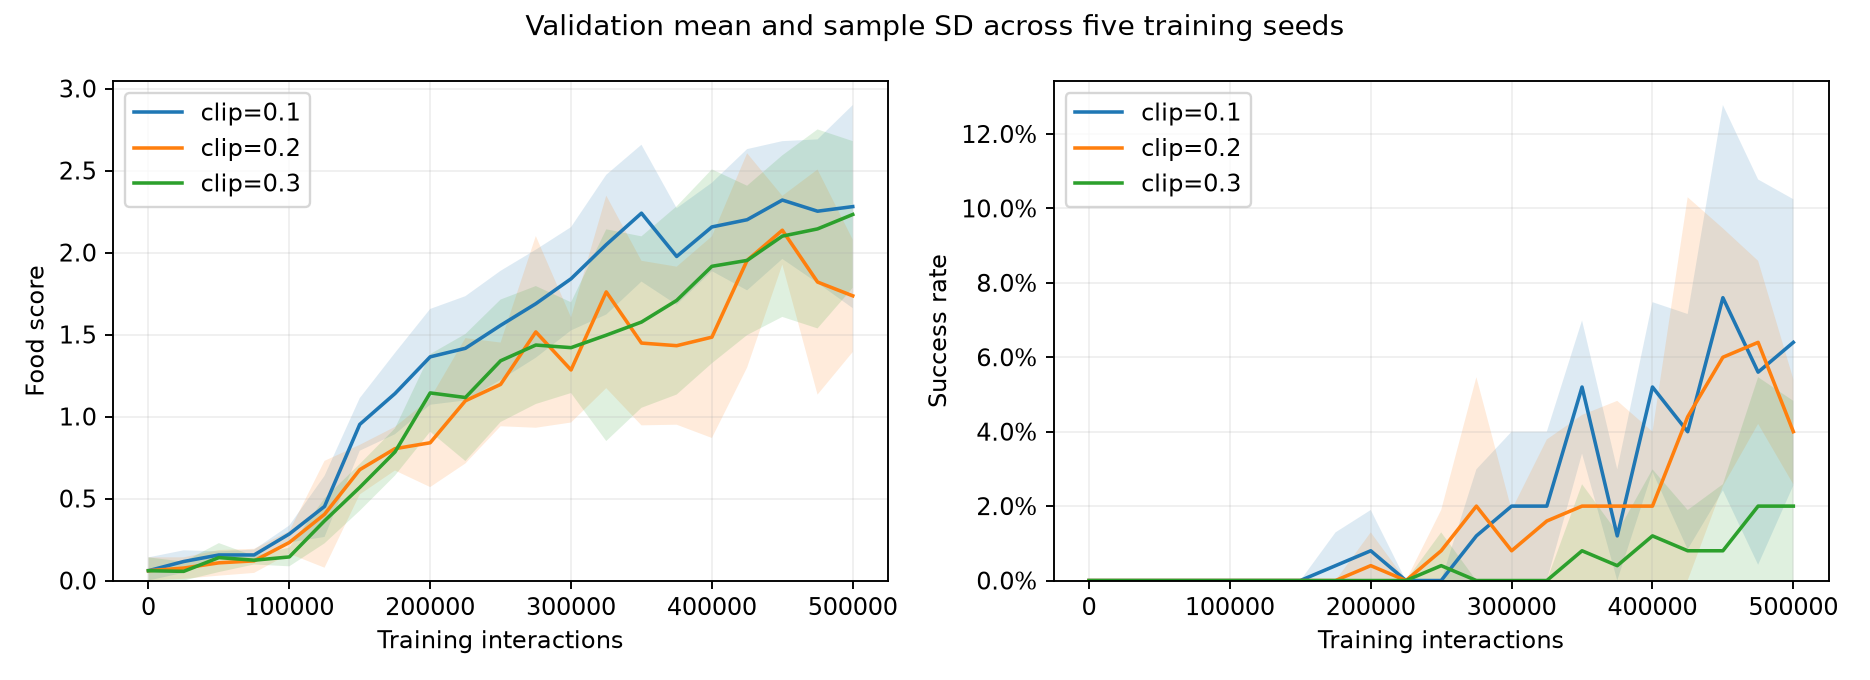

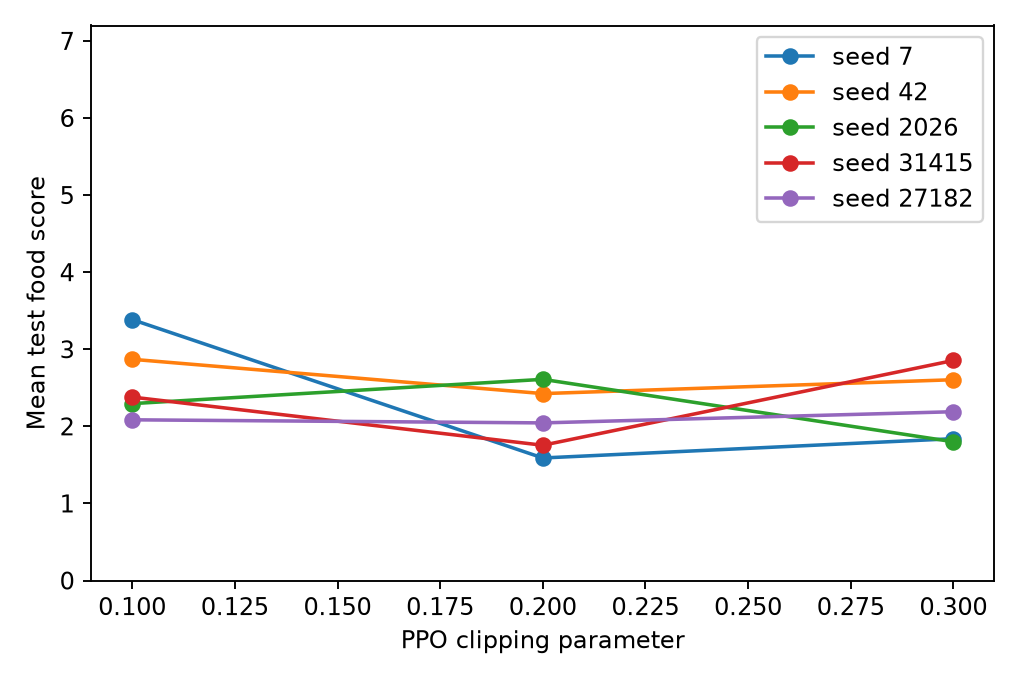

In [6]:
_, terminal_target = compute_gae([2], [5], [True], 100)
np.testing.assert_allclose(terminal_target, [2])
_, bootstrap_target = compute_gae([1], [2], [False], 10, gamma=.9)
np.testing.assert_allclose(bootstrap_target, [10])
print('GAE boundary checks passed. Formal training is complete; reading saved results.')
final_dir=Path('results/final')
display(Markdown((final_dir/'observed_results.md').read_text()))
# Plot the full validation histories; limit rate bands to their valid range.
from matplotlib.ticker import PercentFormatter
fig, axes=plt.subplots(1,2,figsize=(11,4))
for clip in [.1,.2,.3]:
    histories=[json.loads((final_dir/f'seed-{seed}'/f'clip-{clip:.1f}'/'validation.json').read_text()) for seed in [7,42,2026,31415,27182]]
    xs=[row['training_steps'] for row in histories[0]]
    for ax,key in zip(axes,['score','success']):
        ys=np.array([[row[key] for row in h] for h in histories])
        mean=ys.mean(0);sd=ys.std(0,ddof=1)
        ax.plot(xs,mean,label=f'clip={clip}')
        lo=np.maximum(0,mean-sd);hi=np.minimum(1,mean+sd) if key=='success' else mean+sd
        ax.fill_between(xs,lo,hi,alpha=.15)
        ax.set(xlabel='Training interactions',ylabel='Food score' if key=='score' else 'Success rate',ylim=(0,None))
        ax.legend();ax.grid(alpha=.2)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('Validation mean and sample SD across five training seeds')
fig.tight_layout();fig.savefig(final_dir/'figures/learning_curves.png',dpi=170);plt.close(fig)
for name in ['learning_curves.png','paired_scores.png']:
    display(DisplayImage(filename=str(final_dir/'figures'/name)))


## Seed-level results and remaining failures

| Seed | Clip | Selected step | Food score | Success | Timeout |
|---|---|---|---|---|---|
| 7 | 0.1 | 500000 | 3.385 | 18.0% | 56.0% |
| 7 | 0.2 | 450000 | 1.590 | 4.0% | 88.0% |
| 7 | 0.3 | 500000 | 1.840 | 7.5% | 92.0% |
| 42 | 0.1 | 450000 | 2.870 | 13.0% | 68.0% |
| 42 | 0.2 | 425000 | 2.425 | 8.0% | 83.0% |
| 42 | 0.3 | 450000 | 2.605 | 0.0% | 37.0% |
| 2026 | 0.1 | 350000 | 2.295 | 4.0% | 78.0% |
| 2026 | 0.2 | 325000 | 2.610 | 2.5% | 61.5% |
| 2026 | 0.3 | 500000 | 1.800 | 0.0% | 41.0% |
| 31415 | 0.1 | 450000 | 2.380 | 10.5% | 73.0% |
| 31415 | 0.2 | 425000 | 1.755 | 2.0% | 89.0% |
| 31415 | 0.3 | 475000 | 2.855 | 0.0% | 45.0% |
| 27182 | 0.1 | 375000 | 2.085 | 4.0% | 76.5% |
| 27182 | 0.2 | 450000 | 2.045 | 7.5% | 77.0% |
| 27182 | 0.3 | 450000 | 2.190 | 4.5% | 82.0% |

Mean timeout rates are 70.3%, 79.7% and 59.4% for clips 0.1, 0.2 and 0.3. Many revised policies survive longer without collecting all seven foods. The higher success rates therefore do not imply reliable completion; inefficient or repetitive trajectories remain a major failure mode. A timeout alone does not prove that a policy is looping.

## Discussion and limitations

Mean test food scores were 2.603 ± 0.523, 2.085 ± 0.432 and 2.258 ± 0.465 for clipping values 0.1, 0.2 and 0.3. Success rates were 9.9%, 4.8% and 2.4%. Standard deviations describe variation across the five training seeds.

Clip 0.1 had the highest observed mean score and success rate. However, the descriptive paired bootstrap intervals for food-score differences relative to clip 0.2 include zero. Five training seeds provide limited precision, so I do not claim a universally best clipping value.

Timeout rates were 70.3%, 79.7% and 59.4%. Many policies remain alive without collecting all seven foods. The policies therefore do not solve the task reliably. The observation lacks a separate head marker, body order, recent visits and remaining time. Keeping that shared representation limits what a feed-forward policy can distinguish. This experiment does not identify the individual causal effects of representation, sparse rewards or optimization choices.

The test set was not used for checkpoint selection. The independent training seed, rather than each test episode, is the unit of replication. Results should not be directly compared with other group algorithms without matching their training and evaluation protocols.

## Implementation and assistance

The environment and network sizes follow the group setup. The code includes PPO, boundary-aware GAE, validation selection and held-out evaluation. Generative AI assisted implementation, execution checks and drafting; all numerical findings come from the saved runs. The presenting student should be able to explain the method and results.
